In [15]:
import  numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error,r2_score
#load the dataset
california =fetch_california_housing(as_frame=True)
df=california.frame

#Extract feature(AveRooms) and target(MedHousevaal)
X=df[['AveRooms']].values
y=df[['MedHouseVal']].values.reshape(-1,1)

print(f"dataset Loaded successfully.")
print(f"Feature Matrix Shape(X):{X.shape}")
print(f"Target Vector Shape(y):{y.shape}\n")

scaler_X=StandardScaler()
scaler_y=StandardScaler()

X_scaled=scaler_X.fit_transform(X)
y_scaled=scaler_y.fit_transform(y)
m=len(y)
print(df.head)
print(df.describe)
# Add a column of ones to X to handle the intercept/bias term(x_0=1)
X_b = np.c_[np.ones((m,1)),X_scaled]


dataset Loaded successfully.
Feature Matrix Shape(X):(20640, 1)
Target Vector Shape(y):(20640, 1)

<bound method NDFrame.head of        MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0      8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1      8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2      7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3      5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4      3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   
...       ...       ...       ...        ...         ...       ...       ...   
20635  1.5603      25.0  5.045455   1.133333       845.0  2.560606     39.48   
20636  2.5568      18.0  6.114035   1.315789       356.0  3.122807     39.49   
20637  1.7000      17.0  5.205543   1.120092      1007.0  2.325635     39.43   
20638  1.8672      18.0  5.329513   1.171920       741.0  2.123209     

In [24]:

theta_normal_scaled =np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y_scaled)
y_pred_normal_scaled = X_b.dot(theta_normal_scaled)
y_pred_normal=scaler_y.inverse_transform(y_pred_normal_scaled)

def compute_cost(X,y,theta):
    m=len(y)
    predictions = X.dot(theta)
    cost=(1/2*m)*np.sum((predictions-y)**2)
    return cost
def gradient_descent(X,y,theta,learning_rate,iteration):
    m=len(y)
    cost_history=[]
    for i in range(iteration):
        gradients = (1/m)*X.T.dot(X.dot(theta)-y)
        theta=theta-learning_rate*gradients
        cost_history.append(compute_cost(X,y,theta))
    return theta,cost_history
    
learning_rate=0.01
iterations=1500
initial_theta=np.zeros((2,1))
theta_gd_scaled,cost_history = gradient_descent(X_b,y_scaled,initial_theta,learning_rate,iterations)
y_pred_gd_scaled=X_b.dot(theta_gd_scaled)
y_pred_gd=scaler_y.inverse_transform(y_pred_gd_scaled)



In [23]:
mse_normal=mean_squared_error(y,y_pred_normal)
r2_normal=r2_score(y,y_pred_normal)
mse_gd=mean_squared_error(y,y_pred_gd)
r2_gd=r2_score(y,y_pred_gd)
print("------Model Evaluation Results---")
print(f"Normal Equation:\n -Mean squared Error(MSE): {mse_normal:.4f}\n -R-squared(R^2):{r2_normal:4f}")
print(f"Gradient Descent :\n-Mean Squared Error(MSE):{mse_gd:.4f}\n-R--squared(R^2):{r2_gd:.4f}\n")
print(f"Final weight(scaled-Normal Equation:Intercept={theta_normal_scaled[0][0]:.4f},slope={theta_normal_scaled[1][0]:.4f}")
print(f"Final weights(scaled).Gradient Descent:Intercept={theta_gd_scaled[0][0]:.4f},slope={theta_gd_scaled [1][0]:.4f}")

------Model Evaluation Results---
Normal Equation:
 -Mean squared Error(MSE): 1.3008
 -R-squared(R^2):0.023088
Gradient Descent :
-Mean Squared Error(MSE):1.3008
-R--squared(R^2):0.0231

Final weight(scaled-Normal Equation:Intercept=0.0000,slope=0.1519
Final weights(scaled).Gradient Descent:Intercept=0.0000,slope=0.1519


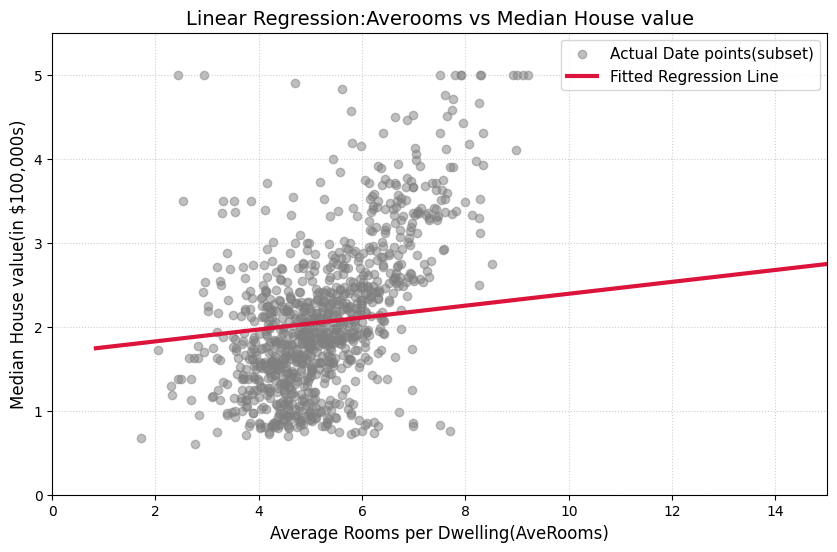

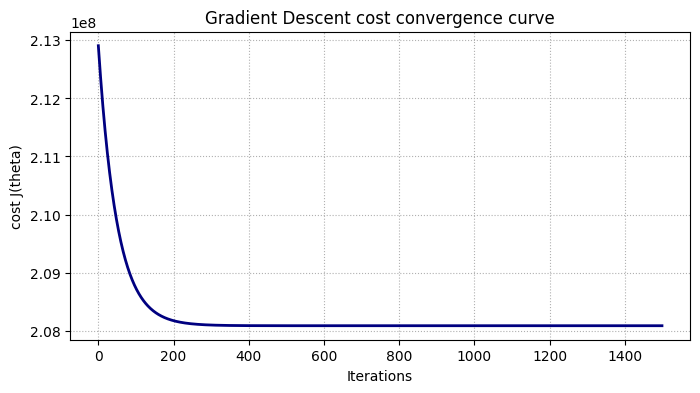

In [22]:
sort_axis=np.argsort(X.flatten())
X_sorted=X[sort_axis]
y_pred_gd_sorted=y_pred_gd[sort_axis]
plt.figure(figsize=(10,6))
plt.scatter(X[:1000],y[:1000],color='gray',alpha=0.5,label='Actual Date points(subset)')
plt.plot(X_sorted,y_pred_gd_sorted,color='Crimson',linewidth=3,label='Fitted Regression Line')

plt.title('Linear Regression:Averooms vs Median House value',fontsize=14)
plt.xlabel('Average Rooms per Dwelling(AveRooms)',fontsize=12)
plt.ylabel('Median House value(in $100,000s)',fontsize=12)
plt.xlim(0,15)
plt.ylim(0,5.5)
plt.legend(fontsize=11)
plt.grid(True,linestyle=':',alpha=0.6)
plt.show()

plt.figure(figsize=(8,4))
plt.plot(range(iterations),cost_history,color='navy',linewidth=2)
plt.title('Gradient Descent cost convergence curve')
plt.xlabel('Iterations')
plt.ylabel('cost J(theta)')
plt.grid(True,linestyle=':')
plt.show()